# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        # batch_first=True: the input has shape (questions, words), so the RNN reads
        # each question word by word
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()  # reset the gradients from the previous step
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

# check how well the model fits the training questions
with torch.no_grad():
    train_acc = (model(X)[0].argmax(1) == y).float().mean().item()
print(f"Training finished! Final loss: {loss.item():.4f} - training accuracy: {train_acc:.2%}")

Training finished! Final loss: 0.0967 - training accuracy: 98.21%


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

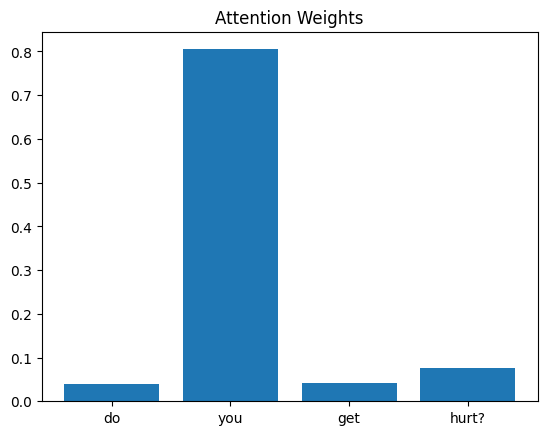

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

### ✅ Solution – Task 1

Two small improvements over Step 6:
- The bar labels are taken from the **tokenizer's own tokens** (the non-zero ids in `X`), not from `question.split()`. The tokenizer removes punctuation (`"hurt?"` → `hurt`), so using its tokens guarantees each bar belongs to the right word.
- Padding positions (id `0`) are left out of the chart.

Q: 'who programmed you?'
   highest attention: "who" (0.777)
   predicted answer : 'People created me.'  (true: 'People created me.')

Q: 'do you have a gender?'
   highest attention: "gender" (0.975)
   predicted answer : "That's a biological concept that doesn't apply to me."  (true: "That's a biological concept that doesn't apply to me.")

Q: 'what is your opinion about ai?'
   highest attention: "about" (0.983)
   predicted answer : 'The world of technology is fascinating.'  (true: 'The world of technology is fascinating.')



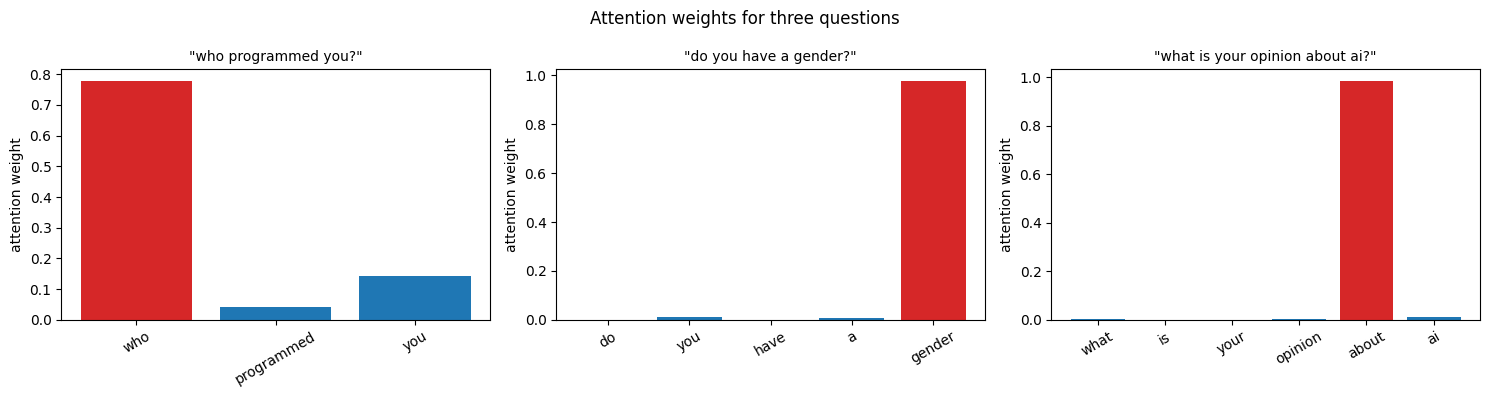

In [7]:
def question_tokens(i):
    """Return the words of question i exactly as the model sees them (no padding)."""
    return [tokenizer.index_word[int(t)] for t in X[i] if t != 0]

def attention_for(i):
    with torch.no_grad():
        logits, weights = model(X[i:i + 1])
    words = question_tokens(i)
    pred = logits.argmax(1).item()
    return words, weights[0, :len(words)].numpy(), pred

def find(q):
    return df.index[df["question"] == q.lower()][0]

chosen = [find("Who programmed you?"),
          find("Do you have a gender?"),
          find("What is your opinion about AI?")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, i in zip(axes, chosen):
    words, w, pred = attention_for(i)
    top = words[w.argmax()]
    colors = ["tab:red" if word == top else "tab:blue" for word in words]
    ax.bar(words, w, color=colors)
    ax.set_title(f'"{df["question"][i]}"', fontsize=10)
    ax.set_ylabel("attention weight")
    ax.tick_params(axis="x", rotation=30)
    print(f'Q: {df["question"][i]!r}')
    print(f'   highest attention: "{top}" ({w.max():.3f})')
    print(f'   predicted answer : {df.loc[df.answer_id == pred, "answer"].iloc[0]!r}'
          f'  (true: {df["answer"][i]!r})\n')
plt.suptitle("Attention weights for three questions")
plt.tight_layout()
plt.show()

**Observations**

| Question | Word with highest attention | Prediction correct? |
|---|---|---|
| who programmed you? | **who** (0.78) | ✅ "People created me." |
| do you have a gender? | **gender** (0.98) | ✅ "That's a biological concept…" |
| what is your opinion about ai? | **about** (0.98) | ✅ "The world of technology is fascinating." |

**Do the highest-attention words look important?** Mostly yes. *gender* is clearly the key word of its question. *who* is the word that distinguishes "who made you" questions from the other groups.
For the AI question the model focuses on *about* rather than *ai* or *opinion*. In this small dataset *about* mainly appears in questions of the "technology" group ("how do you feel **about** AI / tech / the singularity…"), so it is a useful *shortcut* for the model even though a human would pick *AI*.

This shows that attention weights tell us **what the model found useful for its decision**, which is not always what a human considers meaningful. Also, the RNN reads left to right, so the hidden state at *about* already contains information about the words before it; attending to *about* partly means attending to "what is your opinion about".

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

### ✅ Solution – Task 2
Two questions from the same answer group (*"The world of technology is fascinating."*) that mean the same thing but use different words:
- "How do you feel about artificial intelligence?"
- "What is your opinion about AI?"

A second pair from the *"People created me."* group is added for comparison.

How do you feel about artificial intelligence?     top-3 words: about (0.950), artificial (0.025), intelligence (0.023)
What is your opinion about AI?                     top-3 words: about (0.983), ai (0.011), opinion (0.004)

Who built you?                                     top-3 words: who (0.645), built (0.232), you (0.090)
Who programmed you?                                top-3 words: who (0.777), you (0.142), programmed (0.040)



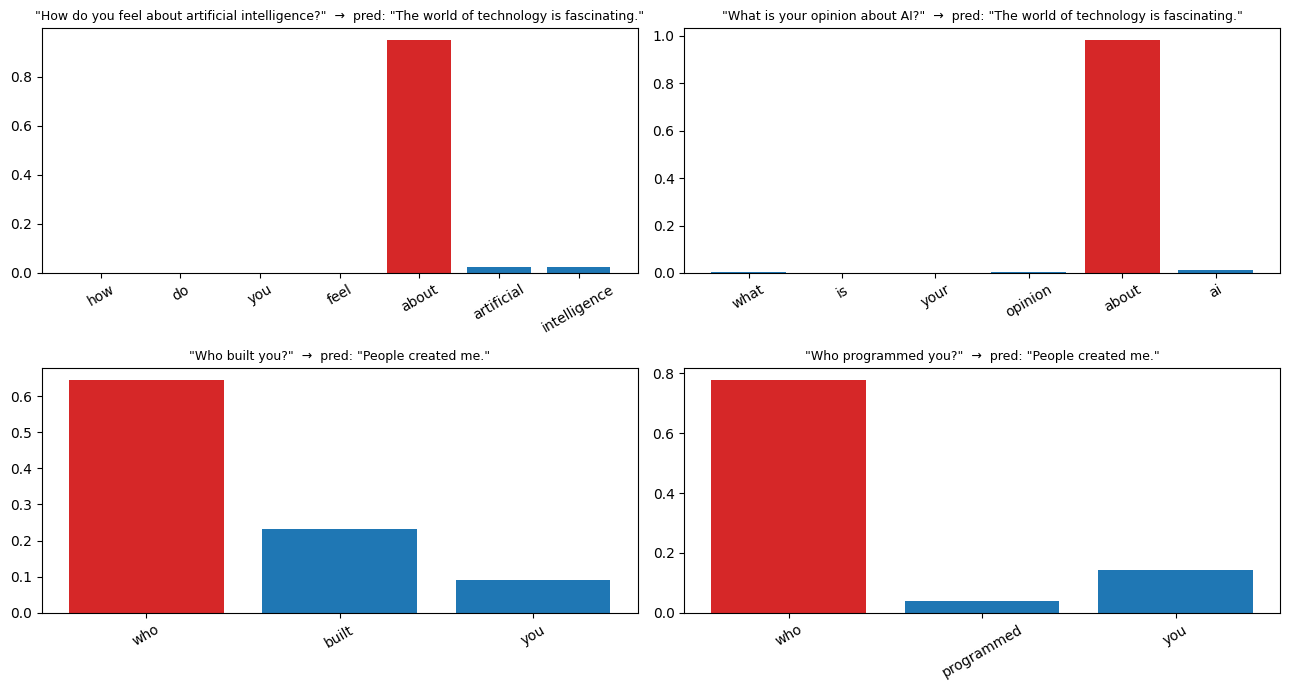

In [8]:
pairs = [("How do you feel about artificial intelligence?", "What is your opinion about AI?"),
         ("Who built you?", "Who programmed you?")]

fig, axes = plt.subplots(len(pairs), 2, figsize=(13, 7))
for row, (q1, q2) in enumerate(pairs):
    for col, q in enumerate((q1, q2)):
        i = find(q)
        words, w, pred = attention_for(i)
        ax = axes[row, col]
        top = words[w.argmax()]
        ax.bar(words, w, color=["tab:red" if x == top else "tab:blue" for x in words])
        ax.set_title(f'"{q}"  →  pred: "{df.loc[df.answer_id == pred, "answer"].iloc[0]}"', fontsize=9)
        ax.tick_params(axis="x", rotation=30)
        ranked = sorted(zip(words, w), key=lambda p: -p[1])[:3]
        print(f"{q:<50} top-3 words: " + ", ".join(f"{a} ({b:.3f})" for a, b in ranked))
    print()
plt.tight_layout()
plt.show()

**Observations**

| Pair (same answer group) | Top word – question A | Top word – question B |
|---|---|---|
| "How do you feel about artificial intelligence?" vs "What is your opinion about AI?" | **about** (0.95) | **about** (0.98) |
| "Who built you?" vs "Who programmed you?" | **who** (0.65), then *built* (0.23) | **who** (0.78), then *you* (0.14), *programmed* (0.04) |

**Does the model focus on similar words?** Yes. In both pairs the two questions put most of their attention on the **same word** (*about*, *who*), even though the rest of the wording is different (*feel / opinion*, *artificial intelligence / AI*, *built / programmed*). Both questions in each pair are also mapped to the correct (same) answer.

**What this suggests about attention:** attention learns which positions are most useful for the *task*, and these are often the words that are shared across a group of paraphrases. That makes the model robust to different wording, but it can also rely on generic "cue words" instead of the real content words: the meaning words *artificial intelligence* / *AI* receive only 1–3 % of the attention. Attention is a trained weighting, not a guarantee of human-like understanding, and with a larger, more varied dataset the model would need to rely more on the content words.